In [1]:
import json
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook

Data Import

In [2]:
runs_rs = pd.read_csv('data/runs_random_search.csv', sep=';')
runs_bo = pd.read_csv('data/runs_bayesian_optimization.csv', sep=';')
runs_ne = pd.read_csv('data/runs_neuroevolution.csv', sep=';')
runs_hybrid = pd.read_csv('data/runs_hybrid.csv', sep=';')
print(runs_hybrid.head())

evals_rs = pd.read_csv('data/evaluations_random_search.csv', sep=';')
evals_bo = pd.read_csv('data/evaluations_bayesian_optimization.csv', sep=';')
evals_ne = pd.read_csv('data/evaluations_neuroevolution.csv', sep=';')
evals_hybrid = pd.read_csv('data/evaluations_hybrid.csv', sep=';')

                                     algorithm     seed  best_accuracy  \
0  bayesian_optimization_neuroevolution_hybrid  5912847       0.981669   
1  bayesian_optimization_neuroevolution_hybrid  1384225       0.987151   
2  bayesian_optimization_neuroevolution_hybrid  6103771       0.984238   
3  bayesian_optimization_neuroevolution_hybrid   482916       0.986694   
4  bayesian_optimization_neuroevolution_hybrid  2947183       0.987322   

   best_precision  best_recall  best_macro_f1  total_search_time  \
0        0.938789     0.881533       0.905794        6606.543336   
1        0.953382     0.904773       0.927167       11218.564896   
2        0.951228     0.884830       0.914385        7937.023099   
3        0.946429     0.916348       0.930689       10495.067009   
4        0.942509     0.915161       0.927792       10376.567510   

   time_to_best  peak_memory_mb  \
0   5541.693985      983.652344   
1   8625.990908      937.550293   
2   2492.575985      381.584961   
3   62

In [3]:
runs = pd.concat([runs_rs, runs_bo, runs_ne, runs_hybrid], ignore_index=True)

evals = pd.concat([evals_rs, evals_bo, evals_ne, evals_hybrid], ignore_index=True)
print(evals.head())
print(len(evals))

       algorithm     seed  evaluation_number  \
0  random_search  5912847                  1   
1  random_search  5912847                  2   
2  random_search  5912847                  3   
3  random_search  5912847                  4   
4  random_search  5912847                  5   

                                   architecture_json  accuracy  precision  \
0  {"learning_rate": 0.005099814555304697, "num_l...  0.932442   0.741631   
1  {"learning_rate": 0.009682511178111397, "num_l...  0.950431   0.841563   
2  {"learning_rate": 0.009690035856308017, "num_l...  0.944035   0.919021   
3  {"learning_rate": 0.009654450899755326, "num_l...  0.929930   0.882988   
4  {"learning_rate": 0.003080982864618174, "num_l...  0.970933   0.930327   

     recall  macro_f1  training_time  peak_memory_mb  
0  0.513405  0.540103      94.498573     1642.132812  
1  0.695111  0.749761      33.791053     1563.593750  
2  0.624521  0.672815      24.541167     1568.750000  
3  0.525321  0.568025     12

Plot Styling

In [4]:
print('Active preset B: RS=#0088ff, BO=#ff0000, NE=#f6d100, BO+NE=#02bb3d')

Active preset B: RS=#0088ff, BO=#ff0000, NE=#f6d100, BO+NE=#02bb3d


Phase 1

Phase 2

In [5]:
rows = []
for algorithm, df in [('random_search', runs_rs), ('bayesian_optimization', runs_bo),
                      ('neuroevolution', runs_ne), ('bayesian_optimization_neuroevolution_hybrid', runs_hybrid)]:
    s = df['time_to_best']
    q1, median, q3 = s.quantile([0.25, 0.5, 0.75])
    rows.append({
        'algorithm': algorithm,
        'time_to_best_mean': s.mean(),
        'time_to_best_sd': s.std(),
        'time_to_best_median': median,
        'time_to_best_iqr': q3 - q1,
        'time_to_best_min': s.min(),
        'time_to_best_max': s.max(),
        'time_to_best_cv': s.std() / s.mean(),
    })

runs_aggregated = pd.DataFrame(rows)
print(runs_aggregated)

                                     algorithm  time_to_best_mean  \
0                                random_search        3066.116830   
1                        bayesian_optimization        7861.961587   
2                               neuroevolution        3441.053886   
3  bayesian_optimization_neuroevolution_hybrid        6220.371131   

   time_to_best_sd  time_to_best_median  time_to_best_iqr  time_to_best_min  \
0      1957.636731          2625.540378       3205.671863        250.522888   
1      3125.136392          7393.071142       4500.228803       1903.329836   
2      2234.226820          3313.167872       1932.140568        249.332546   
3      2952.129549          5637.047300       3962.354359        652.556406   

   time_to_best_max  time_to_best_cv  
0       6940.554206         0.638474  
1      13907.884536         0.397501  
2      11732.212547         0.649286  
3      13938.582908         0.474591  


Phase 3

Test for Normality

In [6]:
metrics = ['best_accuracy', 'best_macro_f1', 'total_search_time', 'time_to_best', 'peak_memory_mb']

shapiro_results = []

for algorithm, group in runs.groupby('algorithm'):
    for metric in metrics:
        statistic, p_value = stats.shapiro(group[metric])
        normal = p_value > 0.05
        shapiro_results.append({
            'algorithm': algorithm,
            'metric': metric,
            'n': 30,
            'statistic': statistic,
            'p_value': p_value,
            'normal': normal,
        })
        print(f"{algorithm} / {metric}: n=30, statistic={statistic}, p_value={p_value}")
        print(f"  {'appears' if normal else 'does not appear'} to be normally distributed.")

    print()

shapiro_df = pd.DataFrame(shapiro_results)
shapiro_df

bayesian_optimization / best_accuracy: n=30, statistic=0.9390873556114505, p_value=0.08595549021288289
  appears to be normally distributed.
bayesian_optimization / best_macro_f1: n=30, statistic=0.9641017015611096, p_value=0.39250978090156724
  appears to be normally distributed.
bayesian_optimization / total_search_time: n=30, statistic=0.9679832718525514, p_value=0.4855725031670534
  appears to be normally distributed.
bayesian_optimization / time_to_best: n=30, statistic=0.9659469117285274, p_value=0.4349946573701089
  appears to be normally distributed.
bayesian_optimization / peak_memory_mb: n=30, statistic=0.9230633642285084, p_value=0.03222992110289696
  does not appear to be normally distributed.

bayesian_optimization_neuroevolution_hybrid / best_accuracy: n=30, statistic=0.9705183439633289, p_value=0.5534545035207861
  appears to be normally distributed.
bayesian_optimization_neuroevolution_hybrid / best_macro_f1: n=30, statistic=0.9643598105570765, p_value=0.398256310370762

,algorithm,metric,n,statistic,p_value,normal
0,bayesian_optimization,best_accuracy,30,0.939087,0.085955,True
1,bayesian_optimization,best_macro_f1,30,0.964102,0.392510,True
2,bayesian_optimization,total_search_time,30,0.967983,0.485573,True
3,bayesian_optimization,time_to_best,30,0.965947,0.434995,True
4,bayesian_optimization,peak_memory_mb,30,0.923063,0.032230,False
5,bayesian_optimization_neuroevolution_hybrid,best_accuracy,30,0.970518,0.553455,True
6,bayesian_optimization_neuroevolution_hybrid,best_macro_f1,30,0.964360,0.398256,True
7,bayesian_optimization_neuroevolution_hybrid,total_search_time,30,0.931002,0.052210,True
8,bayesian_optimization_neuroevolution_hybrid,time_to_best,30,0.966725,0.453875,True
9,bayesian_optimization_neuroevolution_hybrid,peak_memory_mb,30,0.958197,0.278385,True


Omnibus test:

In [7]:
friedman_results = []

for metric in metrics:
    pivot = runs.pivot(index='seed', columns='algorithm', values=metric)
    statistic, p_value = stats.friedmanchisquare(
        pivot['bayesian_optimization'],
        pivot['bayesian_optimization_neuroevolution_hybrid'],
        pivot['neuroevolution'],
        pivot['random_search'],
    )
    significant = p_value < 0.05

    friedman_results.append({
        'metric': metric,
        'n': 30,
        'statistic': statistic,
        'p_value': p_value,
        'significant': significant,
    })

    print(f"{metric}: n=30, statistic={statistic}, p_value={p_value}")
    print(f"  {'significant' if significant else 'not significant'} difference across algorithms.")
    print()

friedman_df = pd.DataFrame(friedman_results)
friedman_df

best_accuracy: n=30, statistic=27.240802675585318, p_value=5.241193159373631e-06
  significant difference across algorithms.

best_macro_f1: n=30, statistic=29.14715719063546, p_value=2.0855127322186156e-06
  significant difference across algorithms.

total_search_time: n=30, statistic=69.0, p_value=6.988237517742192e-15
  significant difference across algorithms.

time_to_best: n=30, statistic=33.960000000000036, p_value=2.0200854878269118e-07
  significant difference across algorithms.

peak_memory_mb: n=30, statistic=25.24000000000001, p_value=1.3755374452002362e-05
  significant difference across algorithms.



,metric,n,statistic,p_value,significant
0,best_accuracy,30,27.240803,5.241193e-06,True
1,best_macro_f1,30,29.147157,2.085513e-06,True
2,total_search_time,30,69.000000,6.988238e-15,True
3,time_to_best,30,33.960000,2.020085e-07,True
4,peak_memory_mb,30,25.240000,1.375537e-05,True


Post-hoc Pairwise:

In [8]:
pairs = [
    ('bayesian_optimization', 'bayesian_optimization_neuroevolution_hybrid'),
    ('bayesian_optimization', 'neuroevolution'),
    ('bayesian_optimization', 'random_search'),
    ('bayesian_optimization_neuroevolution_hybrid', 'neuroevolution'),
    ('bayesian_optimization_neuroevolution_hybrid', 'random_search'),
    ('neuroevolution', 'random_search'),
]

wilcoxon_results = []

for metric in metrics:
    pivot = runs.pivot(index='seed', columns='algorithm', values=metric)

    metric_rows = []
    for algo_a, algo_b in pairs:
        statistic, p_value = stats.wilcoxon(pivot[algo_a], pivot[algo_b])
        metric_rows.append({
            'metric': metric,
            'algorithm_a': algo_a,
            'algorithm_b': algo_b,
            'n': 30,
            'statistic': statistic,
            'p_value': p_value,
        })

    p_values = np.array([row['p_value'] for row in metric_rows])
    order = np.argsort(p_values)
    adjusted = np.empty(6)
    running_max = 0.0
    for rank, idx in enumerate(order):
        adj = min((6 - rank) * p_values[idx], 1.0)
        running_max = max(running_max, adj)
        adjusted[idx] = running_max

    for row, adj in zip(metric_rows, adjusted):
        row['p_value_holm'] = adj
        row['significant'] = adj < 0.05

    wilcoxon_results.extend(metric_rows)

    print(f"{metric}:")
    for row in metric_rows:
        flag = 'significant' if row['significant'] else 'not significant'
        print(f"  {row['algorithm_a']} vs {row['algorithm_b']}: statistic={row['statistic']}, "
              f"p={row['p_value']:.4g}, p_holm={row['p_value_holm']:.4g} ({flag})")
    print()

wilcoxon_df = pd.DataFrame(wilcoxon_results)
wilcoxon_df

best_accuracy:
  bayesian_optimization vs bayesian_optimization_neuroevolution_hybrid: statistic=171.0, p=0.2058, p_holm=0.4117 (not significant)
  bayesian_optimization vs neuroevolution: statistic=75.5, p=0.001241, p_holm=0.004963 (significant)
  bayesian_optimization vs random_search: statistic=125.0, p=0.02703, p_holm=0.08108 (not significant)
  bayesian_optimization_neuroevolution_hybrid vs neuroevolution: statistic=41.0, p=8.177e-05, p_holm=0.0004906 (significant)
  bayesian_optimization_neuroevolution_hybrid vs random_search: statistic=57.5, p=0.0003183, p_holm=0.001591 (significant)
  neuroevolution vs random_search: statistic=162.0, p=0.2301, p_holm=0.4117 (not significant)

best_macro_f1:
  bayesian_optimization vs bayesian_optimization_neuroevolution_hybrid: statistic=216.0, p=0.7457, p_holm=1 (not significant)
  bayesian_optimization vs neuroevolution: statistic=65.0, p=0.0002833, p_holm=0.0008498 (significant)
  bayesian_optimization vs random_search: statistic=48.0, p=4.4

,metric,algorithm_a,algorithm_b,n,statistic,p_value,p_value_holm,significant
0,best_accuracy,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,171.0,2.058403e-01,4.116805e-01,False
1,best_accuracy,bayesian_optimization,neuroevolution,30,75.5,1.240873e-03,4.963491e-03,True
2,best_accuracy,bayesian_optimization,random_search,30,125.0,2.702511e-02,8.107533e-02,False
3,best_accuracy,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,41.0,8.177098e-05,4.906259e-04,True
4,best_accuracy,bayesian_optimization_neuroevolution_hybrid,random_search,30,57.5,3.182963e-04,1.591482e-03,True
5,best_accuracy,neuroevolution,random_search,30,162.0,2.300781e-01,4.116805e-01,False
6,best_macro_f1,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,216.0,7.456547e-01,1.000000e+00,False
7,best_macro_f1,bayesian_optimization,neuroevolution,30,65.0,2.832636e-04,8.497909e-04,True
8,best_macro_f1,bayesian_optimization,random_search,30,48.0,4.407577e-05,2.203789e-04,True
9,best_macro_f1,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,51.0,6.286614e-05,2.514645e-04,True


Matched-Pairs Rank-Biserial Correlation

In [9]:
rank_biserial_results = []

for metric in metrics:
    pivot = runs.pivot(index='seed', columns='algorithm', values=metric)

    for algo_a, algo_b in pairs:
        diff = np.asarray(pivot[algo_a]) - np.asarray(pivot[algo_b])
        diff = diff[diff != 0]
        ranks = stats.rankdata(np.abs(diff))
        w_pos = ranks[diff > 0].sum()
        w_neg = ranks[diff < 0].sum()
        r = (w_pos - w_neg) / (w_pos + w_neg)

        if abs(r) < 0.1:
            magnitude = 'negligible'
        elif abs(r) < 0.3:
            magnitude = 'small'
        elif abs(r) < 0.5:
            magnitude = 'medium'
        else:
            magnitude = 'large'

        rank_biserial_results.append({
            'metric': metric,
            'algorithm_a': algo_a,
            'algorithm_b': algo_b,
            'rank_biserial': r,
            'magnitude': magnitude,
        })

    print(f"{metric}:")
    for row in rank_biserial_results[-6:]:
        print(f"  {row['algorithm_a']} vs {row['algorithm_b']}: r={row['rank_biserial']:.4f} ({row['magnitude']})")
    print()

rank_biserial_df = pd.DataFrame(rank_biserial_results)

results_df = wilcoxon_df.merge(rank_biserial_df, on=['metric', 'algorithm_a', 'algorithm_b'])
results_df

best_accuracy:
  bayesian_optimization vs bayesian_optimization_neuroevolution_hybrid: r=-0.2645 (small)
  bayesian_optimization vs neuroevolution: r=0.6753 (large)
  bayesian_optimization vs random_search: r=0.4624 (medium)
  bayesian_optimization_neuroevolution_hybrid vs neuroevolution: r=0.8237 (large)
  bayesian_optimization_neuroevolution_hybrid vs random_search: r=0.7527 (large)
  neuroevolution vs random_search: r=-0.2552 (small)

best_macro_f1:
  bayesian_optimization vs bayesian_optimization_neuroevolution_hybrid: r=-0.0710 (negligible)
  bayesian_optimization vs neuroevolution: r=0.7204 (large)
  bayesian_optimization vs random_search: r=0.7935 (large)
  bayesian_optimization_neuroevolution_hybrid vs neuroevolution: r=0.7806 (large)
  bayesian_optimization_neuroevolution_hybrid vs random_search: r=0.8839 (large)
  neuroevolution vs random_search: r=-0.0713 (negligible)

total_search_time:
  bayesian_optimization vs bayesian_optimization_neuroevolution_hybrid: r=0.8151 (large)

,metric,algorithm_a,algorithm_b,n,statistic,p_value,p_value_holm,significant,rank_biserial,magnitude
0,best_accuracy,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,171.0,2.058403e-01,4.116805e-01,False,-0.264516,small
1,best_accuracy,bayesian_optimization,neuroevolution,30,75.5,1.240873e-03,4.963491e-03,True,0.675269,large
2,best_accuracy,bayesian_optimization,random_search,30,125.0,2.702511e-02,8.107533e-02,False,0.462366,medium
3,best_accuracy,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,41.0,8.177098e-05,4.906259e-04,True,0.823656,large
4,best_accuracy,bayesian_optimization_neuroevolution_hybrid,random_search,30,57.5,3.182963e-04,1.591482e-03,True,0.752688,large
5,best_accuracy,neuroevolution,random_search,30,162.0,2.300781e-01,4.116805e-01,False,-0.255172,small
6,best_macro_f1,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,216.0,7.456547e-01,1.000000e+00,False,-0.070968,negligible
7,best_macro_f1,bayesian_optimization,neuroevolution,30,65.0,2.832636e-04,8.497909e-04,True,0.720430,large
8,best_macro_f1,bayesian_optimization,random_search,30,48.0,4.407577e-05,2.203789e-04,True,0.793548,large
9,best_macro_f1,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,51.0,6.286614e-05,2.514645e-04,True,0.780645,large


Per Metric Drilldown

=== Test battery: best_accuracy ===

Normality (Shapiro-Wilk):


,algorithm,n,statistic,p_value,normal
0,bayesian_optimization,30,0.939087,0.085955,True
1,bayesian_optimization_neuroevolution_hybrid,30,0.970518,0.553455,True
2,neuroevolution,30,0.948902,0.157975,True
3,random_search,30,0.961564,0.339421,True



Omnibus (Friedman):


,n,statistic,p_value,significant
0,30,27.240803,0.000005,True



Post-hoc (Wilcoxon signed-rank, Holm-corrected) + matched-pairs rank-biserial correlation:


,algorithm_a,algorithm_b,n,statistic,p_value,p_value_holm,significant,rank_biserial,magnitude
0,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,171.0,0.205840,0.411681,False,-0.264516,small
1,bayesian_optimization,neuroevolution,30,75.5,0.001241,0.004963,True,0.675269,large
2,bayesian_optimization,random_search,30,125.0,0.027025,0.081075,False,0.462366,medium
3,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,41.0,0.000082,0.000491,True,0.823656,large
4,bayesian_optimization_neuroevolution_hybrid,random_search,30,57.5,0.000318,0.001591,True,0.752688,large
5,neuroevolution,random_search,30,162.0,0.230078,0.411681,False,-0.255172,small


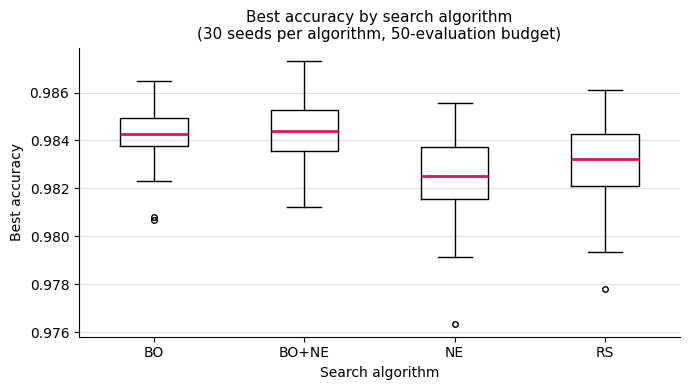


Box plot data (matches the plot above):


,algorithm,whisker_low,q1,median,q3,whisker_high,n_outliers,outliers
0,bayesian_optimization,0.982297,0.983753,0.984267,0.984924,0.986466,2,"[0.9808120609902348, 0.9806978470675576]"
1,bayesian_optimization_neuroevolution_hybrid,0.981212,0.983567,0.984410,0.985266,0.987322,0,[]
2,neuroevolution,0.979156,0.981569,0.982497,0.983710,0.985552,1,[0.9763577180058248]
3,random_search,0.979327,0.982097,0.983239,0.984281,0.986123,1,[0.9777853920392896]


=== Test battery: best_macro_f1 ===

Normality (Shapiro-Wilk):


,algorithm,n,statistic,p_value,normal
0,bayesian_optimization,30,0.964102,0.392510,True
1,bayesian_optimization_neuroevolution_hybrid,30,0.964360,0.398256,True
2,neuroevolution,30,0.956321,0.248757,True
3,random_search,30,0.942265,0.104681,True



Omnibus (Friedman):


,n,statistic,p_value,significant
0,30,29.147157,0.000002,True



Post-hoc (Wilcoxon signed-rank, Holm-corrected) + matched-pairs rank-biserial correlation:


,algorithm_a,algorithm_b,n,statistic,p_value,p_value_holm,significant,rank_biserial,magnitude
0,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,216.0,0.745655,1.000000,False,-0.070968,negligible
1,bayesian_optimization,neuroevolution,30,65.0,0.000283,0.000850,True,0.720430,large
2,bayesian_optimization,random_search,30,48.0,0.000044,0.000220,True,0.793548,large
3,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,51.0,0.000063,0.000251,True,0.780645,large
4,bayesian_optimization_neuroevolution_hybrid,random_search,30,27.0,0.000002,0.000014,True,0.883871,large
5,neuroevolution,random_search,30,202.0,0.737505,1.000000,False,-0.071264,negligible


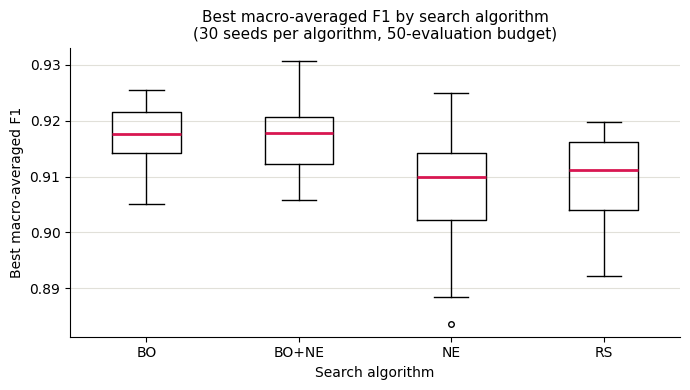


Box plot data (matches the plot above):


,algorithm,whisker_low,q1,median,q3,whisker_high,n_outliers,outliers
0,bayesian_optimization,0.905100,0.914280,0.917539,0.921630,0.925524,0,[]
1,bayesian_optimization_neuroevolution_hybrid,0.905794,0.912311,0.917755,0.920646,0.930689,0,[]
2,neuroevolution,0.888538,0.902278,0.909887,0.914190,0.924935,1,[0.8837087429419348]
3,random_search,0.892193,0.903941,0.911173,0.916099,0.919787,0,[]


=== Test battery: total_search_time ===

Normality (Shapiro-Wilk):


,algorithm,n,statistic,p_value,normal
0,bayesian_optimization,30,0.967983,0.485573,True
1,bayesian_optimization_neuroevolution_hybrid,30,0.931002,0.052210,True
2,neuroevolution,30,0.890431,0.004939,False
3,random_search,30,0.949481,0.163730,True



Omnibus (Friedman):


,n,statistic,p_value,significant
0,30,69.0,6.988238e-15,True



Post-hoc (Wilcoxon signed-rank, Holm-corrected) + matched-pairs rank-biserial correlation:


,algorithm_a,algorithm_b,n,statistic,p_value,p_value_holm,significant,rank_biserial,magnitude
0,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,43.0,2.366677e-05,4.733354e-05,True,0.815054,large
1,bayesian_optimization,neuroevolution,30,0.0,1.862645e-09,1.117587e-08,True,1.000000,large
2,bayesian_optimization,random_search,30,0.0,1.862645e-09,1.117587e-08,True,1.000000,large
3,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,39.0,1.396611e-05,4.189834e-05,True,0.832258,large
4,bayesian_optimization_neuroevolution_hybrid,random_search,30,13.0,1.639128e-07,6.556511e-07,True,0.944086,large
5,neuroevolution,random_search,30,117.0,1.643121e-02,1.643121e-02,True,-0.496774,medium


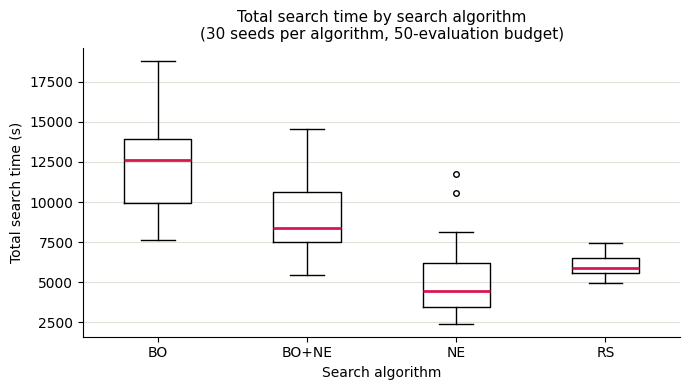


Box plot data (matches the plot above):


,algorithm,whisker_low,q1,median,q3,whisker_high,n_outliers,outliers
0,bayesian_optimization,7605.374092,9934.969936,12625.986197,13939.576087,18809.435887,0,[]
1,bayesian_optimization_neuroevolution_hybrid,5429.783906,7499.242062,8374.559187,10628.639295,14576.336431,0,[]
2,neuroevolution,2415.026062,3469.376421,4431.195941,6178.204816,8156.756270,2,"[11732.26364940009, 10533.1072782001]"
3,random_search,4958.099167,5542.171709,5889.946889,6533.694605,7473.258794,0,[]


=== Test battery: time_to_best ===

Normality (Shapiro-Wilk):


,algorithm,n,statistic,p_value,normal
0,bayesian_optimization,30,0.965947,0.434995,True
1,bayesian_optimization_neuroevolution_hybrid,30,0.966725,0.453875,True
2,neuroevolution,30,0.847504,0.000550,False
3,random_search,30,0.943675,0.114259,True



Omnibus (Friedman):


,n,statistic,p_value,significant
0,30,33.96,2.020085e-07,True



Post-hoc (Wilcoxon signed-rank, Holm-corrected) + matched-pairs rank-biserial correlation:


,algorithm_a,algorithm_b,n,statistic,p_value,p_value_holm,significant,rank_biserial,magnitude
0,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,147.0,8.032736e-02,0.160655,False,0.367742,medium
1,bayesian_optimization,neuroevolution,30,27.0,2.348796e-06,0.000012,True,0.883871,large
2,bayesian_optimization,random_search,30,19.0,5.718321e-07,0.000003,True,0.918280,large
3,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,70.0,4.601069e-04,0.001380,True,0.698925,large
4,bayesian_optimization_neuroevolution_hybrid,random_search,30,56.0,1.105815e-04,0.000442,True,0.759140,large
5,neuroevolution,random_search,30,205.0,5.837571e-01,0.583757,False,0.118280,small


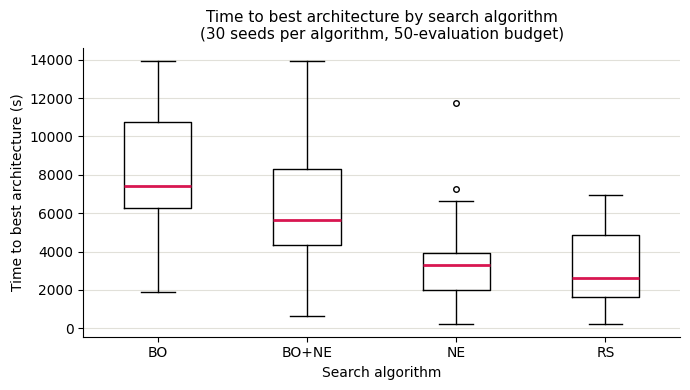


Box plot data (matches the plot above):


,algorithm,whisker_low,q1,median,q3,whisker_high,n_outliers,outliers
0,bayesian_optimization,1903.329836,6250.943022,7393.071142,10751.171825,13907.884536,0,[]
1,bayesian_optimization_neuroevolution_hybrid,652.556406,4355.302617,5637.047300,8317.656976,13938.582908,0,[]
2,neuroevolution,249.332546,2013.337357,3313.167872,3945.477925,6660.212390,2,"[7259.867493900005, 11732.212547099916]"
3,random_search,250.522888,1638.126744,2625.540378,4843.798607,6940.554206,0,[]


=== Test battery: peak_memory_mb ===

Normality (Shapiro-Wilk):


,algorithm,n,statistic,p_value,normal
0,bayesian_optimization,30,0.923063,0.032230,False
1,bayesian_optimization_neuroevolution_hybrid,30,0.958197,0.278385,True
2,neuroevolution,30,0.873306,0.001986,False
3,random_search,30,0.840169,0.000389,False



Omnibus (Friedman):


,n,statistic,p_value,significant
0,30,25.24,0.000014,True



Post-hoc (Wilcoxon signed-rank, Holm-corrected) + matched-pairs rank-biserial correlation:


,algorithm_a,algorithm_b,n,statistic,p_value,p_value_holm,significant,rank_biserial,magnitude
0,bayesian_optimization,bayesian_optimization_neuroevolution_hybrid,30,164.0,1.641841e-01,0.357230,False,0.294624,small
1,bayesian_optimization,neuroevolution,30,22.0,9.983778e-07,0.000006,True,0.905376,large
2,bayesian_optimization,random_search,30,194.0,4.399668e-01,0.439967,False,-0.165591,small
3,bayesian_optimization_neuroevolution_hybrid,neuroevolution,30,57.0,1.233369e-04,0.000493,True,0.754839,large
4,bayesian_optimization_neuroevolution_hybrid,random_search,30,156.0,1.190766e-01,0.357230,False,-0.329032,medium
5,neuroevolution,random_search,30,23.0,1.192093e-06,0.000006,True,-0.901075,large


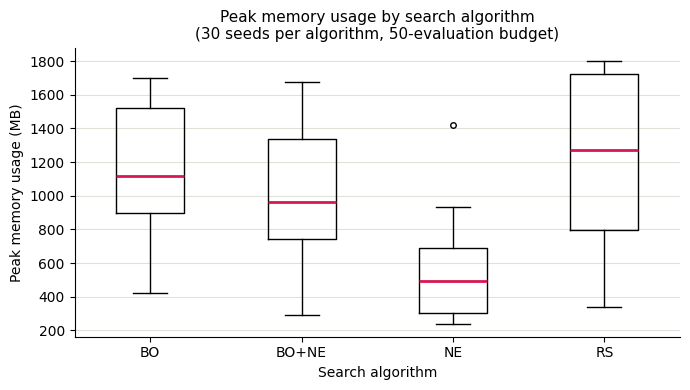


Box plot data (matches the plot above):


,algorithm,whisker_low,q1,median,q3,whisker_high,n_outliers,outliers
0,bayesian_optimization,420.218750,895.093384,1120.184570,1522.617310,1701.257812,0,[]
1,bayesian_optimization_neuroevolution_hybrid,291.472656,743.303833,960.601318,1338.179688,1678.101562,0,[]
2,neuroevolution,240.960938,306.391602,496.088623,688.483276,934.744629,1,[1418.759765625]
3,random_search,337.878418,798.022461,1274.566406,1721.000977,1800.847656,0,[]


In [10]:
plots = [
    ('best_accuracy', 'Best accuracy by search algorithm', 'Best accuracy'),
    ('best_macro_f1', 'Best macro-averaged F1 by search algorithm', 'Best macro-averaged F1'),
    ('total_search_time', 'Total search time by search algorithm', 'Total search time (s)'),
    ('time_to_best', 'Time to best architecture by search algorithm', 'Time to best architecture (s)'),
    ('peak_memory_mb', 'Peak memory usage by search algorithm', 'Peak memory usage (MB)'),
]

for metric, title, ylabel in plots:
    pivot = runs.pivot(index='seed', columns='algorithm', values=metric)

    print(f"=== Test battery: {metric} ===\n")

    print("Normality (Shapiro-Wilk):")
    display(shapiro_df[shapiro_df['metric'] == metric].drop(columns='metric').reset_index(drop=True))

    print("\nOmnibus (Friedman):")
    display(friedman_df[friedman_df['metric'] == metric].drop(columns='metric').reset_index(drop=True))

    print("\nPost-hoc (Wilcoxon signed-rank, Holm-corrected) + matched-pairs rank-biserial correlation:")
    display(results_df[results_df['metric'] == metric].drop(columns='metric').reset_index(drop=True))

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.boxplot(
        [pivot['bayesian_optimization'], pivot['bayesian_optimization_neuroevolution_hybrid'],
         pivot['neuroevolution'], pivot['random_search']],
        tick_labels=['BO', 'BO+NE', 'NE', 'RS'],
        medianprops=dict(color='#D81651', linewidth=2),
        boxprops=dict(color='#000000', linewidth=1),
        whiskerprops=dict(color='#000000', linewidth=1),
        capprops=dict(color='#000000', linewidth=1),
        flierprops=dict(marker='o', markersize=4, markerfacecolor='none',
                        markeredgecolor='#000000', markeredgewidth=1),
    )
    ax.set_title(f"{title}\n(30 seeds per algorithm, 50-evaluation budget)", fontsize=11)
    ax.set_xlabel('Search algorithm')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', color='#e1e0d9', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    fig.tight_layout()
    plt.show()

    print("\nBox plot data (matches the plot above):")
    rows = []
    for algo in pivot.columns:
        s = cbook.boxplot_stats(pivot[algo].values)[0]
        rows.append({
            'algorithm': algo,
            'whisker_low': s['whislo'],
            'q1': s['q1'],
            'median': s['med'],
            'q3': s['q3'],
            'whisker_high': s['whishi'],
            'n_outliers': len(s['fliers']),
            'outliers': list(s['fliers']),
        })
    display(pd.DataFrame(rows))

In [11]:
for metric in metrics:
    pivot = runs.pivot(index='seed', columns='algorithm', values=metric)

    print(f"=== Test battery: {metric} ===\n")

    print("Normality (Shapiro-Wilk):")
    print(shapiro_df[shapiro_df['metric'] == metric].drop(columns='metric').reset_index(drop=True).to_string(index=False))

    print("\nOmnibus (Friedman):")
    print(friedman_df[friedman_df['metric'] == metric].drop(columns='metric').reset_index(drop=True).to_string(index=False))

    print("\nPost-hoc (Wilcoxon signed-rank, Holm-corrected) + matched-pairs rank-biserial correlation:")
    print(results_df[results_df['metric'] == metric].drop(columns='metric').reset_index(drop=True).to_string(index=False))

    print("\nBox plot data:")
    rows = []
    for algo in pivot.columns:
        s = cbook.boxplot_stats(pivot[algo].values)[0]
        rows.append({
            'algorithm': algo,
            'whisker_low': s['whislo'],
            'q1': s['q1'],
            'median': s['med'],
            'q3': s['q3'],
            'whisker_high': s['whishi'],
            'n_outliers': len(s['fliers']),
            'outliers': list(s['fliers']),
        })
    print(pd.DataFrame(rows).to_string(index=False))
    print()

=== Test battery: best_accuracy ===

Normality (Shapiro-Wilk):


                                  algorithm  n  statistic  p_value  normal
                      bayesian_optimization 30   0.939087 0.085955    True
bayesian_optimization_neuroevolution_hybrid 30   0.970518 0.553455    True
                             neuroevolution 30   0.948902 0.157975    True
                              random_search 30   0.961564 0.339421    True

Omnibus (Friedman):
 n  statistic  p_value  significant
30  27.240803 0.000005         True

Post-hoc (Wilcoxon signed-rank, Holm-corrected) + matched-pairs rank-biserial correlation:


                                algorithm_a                                 algorithm_b  n  statistic  p_value  p_value_holm  significant  rank_biserial magnitude
                      bayesian_optimization bayesian_optimization_neuroevolution_hybrid 30      171.0 0.205840      0.411681        False      -0.264516     small
                      bayesian_optimization                              neuroevolution 30       75.5 0.001241      0.004963         True       0.675269     large
                      bayesian_optimization                               random_search 30      125.0 0.027025      0.081075        False       0.462366    medium
bayesian_optimization_neuroevolution_hybrid                              neuroevolution 30       41.0 0.000082      0.000491         True       0.823656     large
bayesian_optimization_neuroevolution_hybrid                               random_search 30       57.5 0.000318      0.001591         True       0.752688     large
                      

Pairwise Difference Magnitudes

In [12]:
diff_results = []
for metric in ['best_accuracy', 'best_macro_f1', 'total_search_time', 'time_to_best']:
    pivot = runs.pivot(index='seed', columns='algorithm', values=metric)
    for algo_a, algo_b, pair in [
        ('bayesian_optimization', 'bayesian_optimization_neuroevolution_hybrid', 'BO vs BO+NE'),
        ('bayesian_optimization', 'neuroevolution', 'BO vs NE'),
        ('bayesian_optimization', 'random_search', 'BO vs RS'),
        ('bayesian_optimization_neuroevolution_hybrid', 'neuroevolution', 'BO+NE vs NE'),
        ('bayesian_optimization_neuroevolution_hybrid', 'random_search', 'BO+NE vs RS'),
        ('neuroevolution', 'random_search', 'NE vs RS'),
    ]:
        diff_results.append({
            'pair': pair,
            'metric': metric,
            'diff': (pivot[algo_a] - pivot[algo_b]).mean(),
        })

diff_table = pd.DataFrame(diff_results).pivot(index='pair', columns='metric', values='diff')
diff_table = diff_table[['best_accuracy', 'best_macro_f1', 'total_search_time', 'time_to_best']]
diff_table

metric,best_accuracy,best_macro_f1,total_search_time,time_to_best
pair,,,,
BO vs BO+NE,-0.000432,-0.000332,3290.523780,1641.590456
BO vs NE,0.001784,0.009820,7262.033991,4420.907701
BO vs RS,0.001119,0.008336,6491.509633,4795.844757
BO+NE vs NE,0.002216,0.010152,3971.510211,2779.317245
BO+NE vs RS,0.001551,0.008669,3200.985853,3154.254301
NE vs RS,-0.000664,-0.001483,-770.524358,374.937055


Performance–Efficiency Trade-off

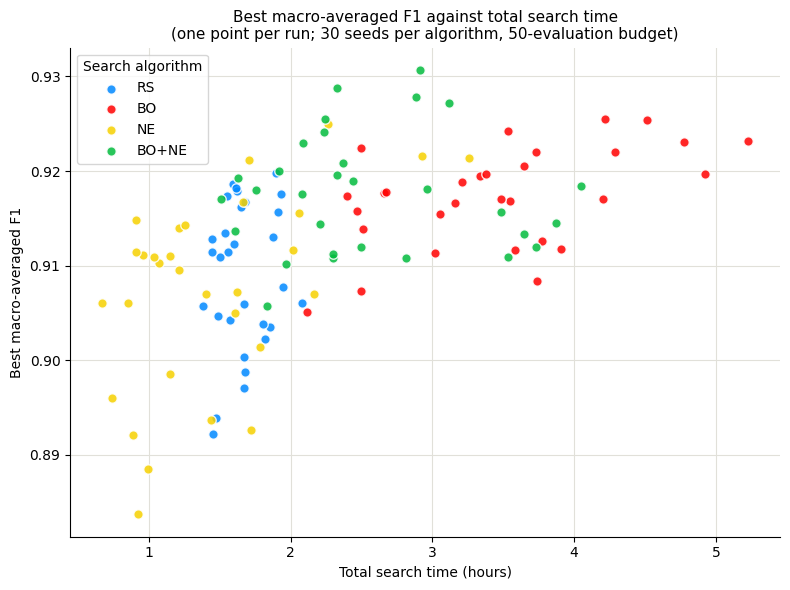

                                  algorithm    seed  best_macro_f1  total_search_time_hours
                      bayesian_optimization 1761334       0.905100                 2.112604
                      bayesian_optimization 5774201       0.917387                 2.394745
                      bayesian_optimization 6103771       0.915748                 2.470615
                      bayesian_optimization 3092518       0.907293                 2.497256
                      bayesian_optimization 6521908       0.922390                 2.499075
                      bayesian_optimization 2839145       0.913868                 2.510848
                      bayesian_optimization 2947183       0.917692                 2.658899
                      bayesian_optimization 4102673       0.917791                 2.674200
                      bayesian_optimization 2214775       0.911301                 3.016256
                      bayesian_optimization  219764       0.915517              

In [13]:
perf_time_df = runs[['algorithm', 'seed', 'total_search_time', 'best_macro_f1']].copy()
perf_time_df['total_search_time_hours'] = perf_time_df['total_search_time'] / 3600
perf_time_df = perf_time_df.drop(columns='total_search_time')

fig, ax = plt.subplots(figsize=(8, 6))
for algo, label, colour in [('random_search', 'RS', '#0088ff'),
                            ('bayesian_optimization', 'BO', '#ff0000'),
                            ('neuroevolution', 'NE', '#f6d100'),
                            ('bayesian_optimization_neuroevolution_hybrid', 'BO+NE', '#02bb3d')]:
    group = runs[runs['algorithm'] == algo]
    ax.scatter(group['total_search_time'] / 3600, group['best_macro_f1'],
               s=46, alpha=0.85, linewidths=1.0, edgecolors='white',
               color=colour, marker='o', label=label)

ax.set_xlabel('Total search time (hours)')
ax.set_ylabel('Best macro-averaged F1')
ax.set_title('Best macro-averaged F1 against total search time\n'
             '(one point per run; 30 seeds per algorithm, 50-evaluation budget)', fontsize=11)
ax.legend(title='Search algorithm')
ax.grid(axis='both', color='#e1e0d9', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()
plt.show()

print(perf_time_df.sort_values(['algorithm', 'total_search_time_hours']).to_string(index=False))

Architectur Level Comparisons

In [14]:
rows = []
for algorithm, group in runs.groupby('algorithm'):
    seqs = []
    vecs = []
    for s in group['best_architecture']:
        arch = json.loads(s)
        seqs.append([layer['layer_type'] for layer in arch['layers']])

        vec = [(arch['learning_rate'] - 0.0001) / (0.01 - 0.0001), (arch['num_layers'] - 1) / 4]
        for i in range(5):
            if i < len(arch['layers']):
                layer = arch['layers'][i]
                vec.extend([1.0 if layer['layer_type'] == c else 0.0 for c in ['CNN', 'LSTM', 'GRU']])
                vec.append((layer['hidden_size'] - 16) / 240)
                vec.append(layer['dropout'] / 0.5)
                vec.extend([1.0 if layer['activation'] == c else 0.0 for c in ['relu', 'tanh', 'elu']])
                if layer['kernel_size'] is None:
                    vec.append(0.0)
                else:
                    vec.append((layer['kernel_size'] - 3) / 4)
                vec.append(1.0 if layer['bidirectional'] else 0.0)
                vec.extend([1.0 if layer['pooling'] == c else 0.0 for c in [None, 'max', 'avg']])
            else:
                vec.extend([0.0] * 13)
        vecs.append(np.array(vec))

    edit_dists = []
    euclid_dists = []
    for i in range(30):
        for j in range(i + 1, 30):
            seq_a = seqs[i]
            seq_b = seqs[j]
            dp = list(range(len(seq_b) + 1))
            for x in range(1, len(seq_a) + 1):
                prev = dp[0]
                dp[0] = x
                for y in range(1, len(seq_b) + 1):
                    temp = dp[y]
                    cost = 0 if seq_a[x - 1] == seq_b[y - 1] else 1
                    dp[y] = min(dp[y] + 1, dp[y - 1] + 1, prev + cost)
                    prev = temp
            edit_dists.append(dp[-1])
            euclid_dists.append(np.linalg.norm(vecs[i] - vecs[j]))

    rows.append({
        'algorithm': algorithm,
        'n_architectures': 30.0,
        'n_pairs': 435.0,
        'mean_edit_distance': np.mean(edit_dists),
        'mean_euclidean_distance': np.mean(euclid_dists),
    })

diversity_df = pd.DataFrame(rows)
diversity_df

,algorithm,n_architectures,n_pairs,mean_edit_distance,mean_euclidean_distance
0,bayesian_optimization,30.0,435.0,2.305747,3.906540
1,bayesian_optimization_neuroevolution_hybrid,30.0,435.0,2.422989,4.435571
2,neuroevolution,30.0,435.0,2.471264,4.454613
3,random_search,30.0,435.0,2.597701,4.654639


Complexity vs Performance

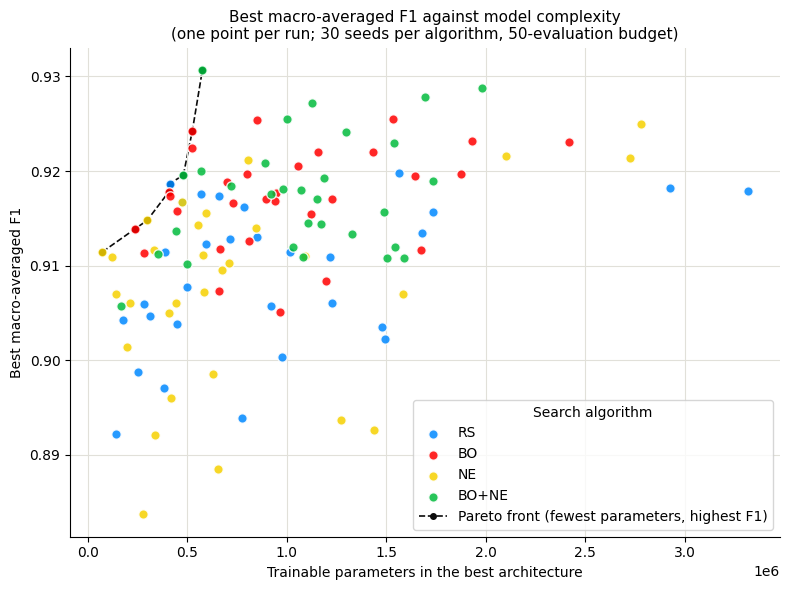

Pareto-optimal runs: 8 of 120

                                  algorithm    seed  param_count  best_macro_f1
                             neuroevolution 5774201        72837       0.911464
                      bayesian_optimization 2839145       235110       0.913868
                             neuroevolution 5026490       298027       0.914799
                      bayesian_optimization 4102673       405597       0.917791
                              random_search 6103771       410017       0.918672
bayesian_optimization_neuroevolution_hybrid 5331909       479295       0.919569
                      bayesian_optimization 5912847       524715       0.924259
bayesian_optimization_neuroevolution_hybrid  482916       575240       0.930689

Pareto front count by algorithm:
algorithm
bayesian_optimization                          3
neuroevolution                                 2
bayesian_optimization_neuroevolution_hybrid    2
random_search                                  1


In [15]:
param_counts = []
for s in runs['best_architecture']:
    arch = json.loads(s)
    in_channels = 1
    total = 0
    for layer in arch['layers']:
        hidden = layer['hidden_size']
        if layer['layer_type'] == 'CNN':
            k = layer['kernel_size'] or 3
            total += in_channels * hidden * k + hidden
            in_channels = hidden
        else:
            gates = 4 if layer['layer_type'] == 'LSTM' else 3
            directions = 2 if layer['bidirectional'] else 1
            total += (gates * hidden * (in_channels + hidden) + gates * 2 * hidden) * directions
            in_channels = hidden * directions
    total += in_channels * 5 + 5
    param_counts.append(total)

complexity_perf_df = runs.copy()
complexity_perf_df['param_count'] = param_counts

fig, ax = plt.subplots(figsize=(8, 6))
for algo, label, colour in [('random_search', 'RS', '#0088ff'),
                            ('bayesian_optimization', 'BO', '#ff0000'),
                            ('neuroevolution', 'NE', '#f6d100'),
                            ('bayesian_optimization_neuroevolution_hybrid', 'BO+NE', '#02bb3d')]:
    group = complexity_perf_df[complexity_perf_df['algorithm'] == algo]
    ax.scatter(group['param_count'], group['best_macro_f1'],
               s=46, alpha=0.85, linewidths=1.0, edgecolors='white',
               color=colour, marker='o', label=label)

pts = complexity_perf_df[['param_count', 'best_macro_f1']].to_numpy()
order = np.lexsort((-pts[:, 1], pts[:, 0]))
pareto_mask = np.zeros(len(pts), dtype=bool)
best_so_far = -np.inf
for idx in order:
    if pts[idx, 1] > best_so_far:
        pareto_mask[idx] = True
        best_so_far = pts[idx, 1]

pareto_df = (complexity_perf_df.loc[pareto_mask, ['algorithm', 'seed', 'param_count', 'best_macro_f1']]
             .sort_values('param_count')
             .reset_index(drop=True))

ax.plot(pareto_df['param_count'], pareto_df['best_macro_f1'], color='#0b0b0b', linestyle='--',
        linewidth=1.2, marker='o', markersize=4, zorder=0, label='Pareto front (fewest parameters, highest F1)')

ax.set_xlabel('Trainable parameters in the best architecture')
ax.set_ylabel('Best macro-averaged F1')
ax.set_title('Best macro-averaged F1 against model complexity\n'
             '(one point per run; 30 seeds per algorithm, 50-evaluation budget)', fontsize=11)
ax.legend(title='Search algorithm')
ax.grid(axis='both', color='#e1e0d9', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()
plt.show()

print(f"Pareto-optimal runs: {len(pareto_df)} of {len(complexity_perf_df)}\n")
print(pareto_df.to_string(index=False))
print("\nPareto front count by algorithm:")
print(pareto_df['algorithm'].value_counts().to_string())

In [16]:
rows = []
for algo, group in evals.groupby('algorithm'):
    for seed, run_evals in group.groupby('seed'):
        if algo == 'bayesian_optimization_neuroevolution_hybrid':
            rows.append({'algorithm': algo, 'seed': seed, 'screened': 1322})
        else:
            rows.append({'algorithm': algo, 'seed': seed, 'screened': len(run_evals)})
screened_runs = pd.DataFrame(rows)

screen_table = (screened_runs.groupby('algorithm')['screened']
                .agg(runs='size', mean='mean', sd='std', min='min', max='max')
                .reindex(['random_search', 'bayesian_optimization', 'neuroevolution',
                          'bayesian_optimization_neuroevolution_hybrid'])
                .reset_index())
screen_table.insert(0, 'method', ['RS', 'BO', 'NE', 'BO+NE'])
screen_table = screen_table.drop(columns='algorithm').round(1)

print("Architectures screened per run (30 seeds per algorithm, 50-evaluation budget)\n")
print(screen_table.to_string(index=False))
display(screen_table)

Architectures screened per run (30 seeds per algorithm, 50-evaluation budget)

method  runs   mean  sd  min  max
    RS    30   50.0 0.0   50   50
    BO    30   50.0 0.0   50   50
    NE    30   40.8 4.0   31   48
 BO+NE    30 1322.0 0.0 1322 1322


,method,runs,mean,sd,min,max
0,RS,30,50.0,0.0,50,50
1,BO,30,50.0,0.0,50,50
2,NE,30,40.8,4.0,31,48
3,BO+NE,30,1322.0,0.0,1322,1322


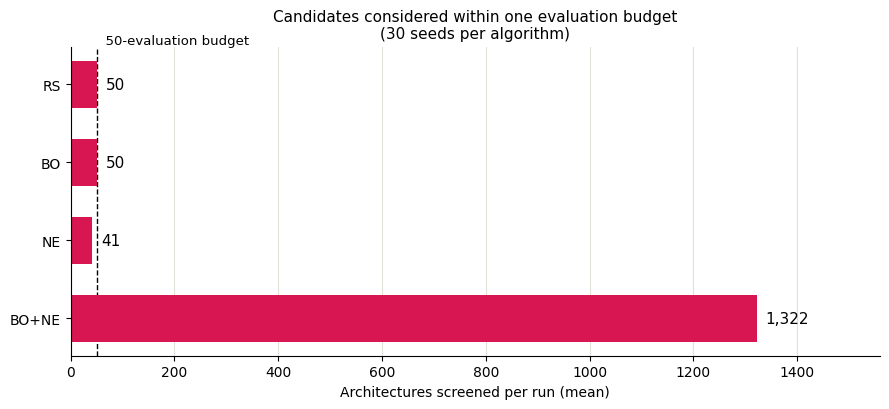

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.2))

vals = np.array([1322.0, 40.8, 50.0, 50.0])
y = np.arange(4)

ax.barh(y, vals, height=.6, color='#D81651')
for i, v in enumerate(vals):
    ax.text(v + 1322.0 * .013, i, f'{v:,.0f}', va='center', fontsize=11)

ax.axvline(50, color='#000000', linestyle='--', linewidth=1, zorder=0)
ax.text(50, 3.48, '  50-evaluation budget', fontsize=9.5, color='#000000', va='bottom')

ax.set_yticks(y, ['BO+NE', 'NE', 'BO', 'RS'])
ax.set_xlabel('Architectures screened per run (mean)')
ax.set_title('Candidates considered within one evaluation budget\n(30 seeds per algorithm)', fontsize=11)
ax.set_xlim(0, 1322.0 * 1.18)
ax.grid(axis='x', color='#e1e0d9', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()
plt.show()

Poster Graphics


Architectures Screened per Run